# 38 - System II SBC Repair Experiments

Follow-up to notebook 37. The 5k true simulator-generated lognormal-prior run improved over the resampled-bank diagnostic but still failed SBC seed stability. This notebook gathers the next plausible repair moves in one place, without changing notebook 37.

The experiments are ordered from cheapest/least invasive to more structural:

1. **Summary preprocessing sweep** on the existing 5k true-lognormal matched bank.
2. **Fixed-nominal warm-start ablation** to test whether the per-draw steady-state map is the main source of nonlinear geometry.
3. **Logit-parameter-space training scaffold** to test whether bounded-support geometry, rather than rejection after sampling, is the calibration bottleneck.

Run sections independently. Do not promote any posterior from this notebook until a reduced experiment gives stable seed behaviour and then survives a larger SBC confirmation.

In [1]:
import json, pathlib, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats as scipy_stats

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from sbi.inference import SNPE
from sbi.neural_nets import posterior_nn
from cstr_sbi.recycle.physics import PARAM_NAMES
from cstr_sbi.recycle.priors import PRIOR_LOW_5D, PRIOR_HIGH_5D
from cstr_sbi.recycle.summaries import summary_names
from sbi_pipeline import _structure_config, _simulate_summary

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
SBI_LOGS = ROOT / 'sbi-logs'
FIGURES = ROOT / 'figures'
for path in [DATA, RESULTS, SBI_LOGS, FIGURES]:
    path.mkdir(exist_ok=True)

STRUCTURE = 'S-B'
NOISE_PCT = 0.003
ARCH = 'zuko_nsf'
HIDDEN = 60
TRANSFORMS = 3
MAX_EPOCHS = 120
STOP_AFTER_EPOCHS = 12
N_POST = 120

NOMINAL_THETA = np.array([1.0, 1.0, 1.0, 1.0, 0.90], dtype=np.float32)
LOG_SIGMA = np.array([0.16, 0.16, 0.10, 0.16, 0.055], dtype=np.float32)

MATCHED_LOGN_BANK_5K = DATA / 'wu2003_sbi_train_sb_lognormal_true_n5000.npz'
MATCHED_LOGN_SBC_SET = RESULTS / '37_sysII_lognormal_sbc_set_n120.npz'
assert MATCHED_LOGN_BANK_5K.exists(), MATCHED_LOGN_BANK_5K
assert MATCHED_LOGN_SBC_SET.exists(), MATCHED_LOGN_SBC_SET

print(f'ROOT={ROOT}')
print(f'Parameters: {PARAM_NAMES}')
print(f'Using matched 5k lognormal bank: {MATCHED_LOGN_BANK_5K}')
print(f'Using shared lognormal SBC set: {MATCHED_LOGN_SBC_SET}')

/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT=/Users/simo/inso-po-RD/cstr-model-optimisation/research_project
Parameters: ['alpha', 'beta_r', 'eta_col', 'xi_reb', 'z_A0_eff']
Using matched 5k lognormal bank: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/wu2003_sbi_train_sb_lognormal_true_n5000.npz
Using shared lognormal SBC set: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/37_sysII_lognormal_sbc_set_n120.npz


## 1. Starting Evidence From Notebook 37

Notebook 37's 5k true-lognormal run gave 0/4 passing seeds at `N_SBC=120`, `N_POST=120`. The best seed reached only min-KS `p = 2.21e-3`. So the prior hypothesis helped relative to the resampled-bank diagnostic, but it did not solve calibration.

The next experiments should answer narrower questions:

- Does robust treatment of the heavy-tailed summary dimensions improve seed stability?
- Does calibration improve if the initial condition is fixed nominal rather than matched per draw?
- Does training in unconstrained logit parameter space improve bounded-support geometry?

In [2]:
for path in [
    RESULTS / '37_sysII_lognormal_true_bank_n5000_sbc.csv',
    RESULTS / '37_sysII_lognormal_true_n5000_preprocess_sbc.csv',
    RESULTS / '37_sysII_lognormal_fixed_y0_n3000_sbc.csv',
]:
    if path.exists():
        print(f'\n### {path.name}')
        df = pd.read_csv(path)
        if 'preprocess' in df.columns:
            display(df.groupby('preprocess')['min_ks_pvalue'].agg(['count', 'max', 'median', 'min']).sort_values('max', ascending=False))
        else:
            display(df.sort_values('min_ks_pvalue', ascending=False))
    else:
        print(f'MISSING: {path}')


### 37_sysII_lognormal_true_bank_n5000_sbc.csv


,seed,n_train,train_wall_s,sbc_wall_s,min_ks_pvalue,sample_seconds_mean,sample_seconds_p95,sample_seconds_max,alpha_ks_pvalue,alpha_mean_rank_frac,beta_r_ks_pvalue,beta_r_mean_rank_frac,eta_col_ks_pvalue,eta_col_mean_rank_frac,xi_reb_ks_pvalue,xi_reb_mean_rank_frac,z_A0_eff_ks_pvalue,z_A0_eff_mean_rank_frac
0,2,5000,18.656406,1.185245,2.210076e-03,0.009769,0.015884,0.016605,1.453546e-02,0.553958,0.070267,0.537847,0.002210,0.427292,0.014535,0.490486,8.029228e-03,0.559444
1,1,5000,15.261527,1.195773,1.104713e-04,0.009870,0.015873,0.016892,8.029228e-03,0.577500,0.001101,0.572500,0.000110,0.609167,0.025429,0.443403,4.299596e-02,0.510069
2,3,5000,14.784743,1.299036,8.077343e-06,0.010699,0.016281,0.058780,1.104713e-04,0.420069,0.249912,0.528264,0.008029,0.562361,0.486298,0.496736,8.077343e-06,0.413403
3,0,5000,19.661602,1.171957,4.488623e-10,0.009630,0.015715,0.018271,1.496804e-07,0.392500,0.070267,0.532083,0.025429,0.528750,0.001101,0.416736,4.488623e-10,0.353819



### 37_sysII_lognormal_true_n5000_preprocess_sbc.csv


,count,max,median,min
preprocess,,,,
drop_heavy_tail,3,0.001101,0.000530,5.043255e-08
identity,3,0.000530,0.000246,4.488623e-10
robust_clip_scale,3,0.000530,0.000246,1.104713e-04
signed_log_robust,3,0.000246,0.000008,1.496804e-07



### 37_sysII_lognormal_fixed_y0_n3000_sbc.csv


,seed,n_train,train_wall_s,sbc_wall_s,min_ks_pvalue,sample_seconds_mean,sample_seconds_p95,sample_seconds_max,alpha_ks_pvalue,alpha_mean_rank_frac,beta_r_ks_pvalue,beta_r_mean_rank_frac,eta_col_ks_pvalue,eta_col_mean_rank_frac,xi_reb_ks_pvalue,xi_reb_mean_rank_frac,z_A0_eff_ks_pvalue,z_A0_eff_mean_rank_frac
0,0,3000,6.850287,1.289603,2.461911e-04,0.010646,0.016492,0.017968,2.461911e-04,0.621667,0.042996,0.542917,0.004286,0.428611,0.025429,0.472431,0.000246,0.592222
1,2,3000,7.761855,1.920170,4.785836e-05,0.015848,0.033670,0.210925,4.299596e-02,0.442569,0.169461,0.527500,0.000048,0.405139,0.070267,0.557639,0.169461,0.514514
2,1,3000,12.125828,1.170069,4.283039e-07,0.009658,0.016354,0.025384,4.283039e-07,0.617083,0.110999,0.528472,0.000003,0.611806,0.002210,0.543750,0.000110,0.552153


## 2. Shared Prior And SBC Utilities

Use the same truncated lognormal prior as notebook 37. The class is a real `torch.distributions.Distribution`, so it can be passed to `sbi.SNPE`.

In [3]:
class TruncatedLogNormalPrior(torch.distributions.Distribution):
    arg_constraints = {}
    has_rsample = False

    def __init__(self, median, sigma, low, high, validate_args=False):
        self.median = torch.as_tensor(median, dtype=torch.float32)
        self.sigma = torch.as_tensor(sigma, dtype=torch.float32)
        self.low = torch.as_tensor(low, dtype=torch.float32)
        self.high = torch.as_tensor(high, dtype=torch.float32)
        self.mu = torch.log(self.median)
        self.base = torch.distributions.Normal(self.mu, self.sigma)
        lo_z = (torch.log(self.low) - self.mu) / self.sigma
        hi_z = (torch.log(self.high) - self.mu) / self.sigma
        standard = torch.distributions.Normal(torch.zeros_like(self.mu), torch.ones_like(self.mu))
        self.log_norm = torch.log(standard.cdf(hi_z) - standard.cdf(lo_z)).sum()
        super().__init__(batch_shape=torch.Size(), event_shape=torch.Size([len(self.median)]), validate_args=validate_args)

    def sample(self, sample_shape=torch.Size()):
        if isinstance(sample_shape, int):
            sample_shape = torch.Size([sample_shape])
        sample_shape = torch.Size(sample_shape)
        n = int(np.prod(sample_shape)) if len(sample_shape) else 1
        accepted = []
        batch = max(1024, 2 * n)
        while sum(a.shape[0] for a in accepted) < n:
            theta = torch.exp(self.base.sample((batch,)))
            mask = ((theta >= self.low) & (theta <= self.high)).all(dim=1)
            if mask.any():
                accepted.append(theta[mask])
        out = torch.cat(accepted, dim=0)[:n]
        return out.reshape(sample_shape + self.event_shape)

    def log_prob(self, value):
        value = torch.as_tensor(value, dtype=torch.float32)
        inside = ((value >= self.low) & (value <= self.high)).all(dim=-1)
        safe_value = torch.clamp(value, min=torch.finfo(torch.float32).tiny)
        logpdf = self.base.log_prob(torch.log(safe_value)).sum(dim=-1) - torch.log(safe_value).sum(dim=-1) - self.log_norm
        return torch.where(inside, logpdf, torch.full_like(logpdf, -torch.inf))

prior_logn = TruncatedLogNormalPrior(NOMINAL_THETA, LOG_SIGMA, PRIOR_LOW_5D, PRIOR_HIGH_5D)
summary_name_list = summary_names(STRUCTURE)
print('Prior ready. Summary dimensions:', len(summary_name_list))

Prior ready. Summary dimensions: 66


## 3. Experiment A - Summary Preprocessing Sweep

This experiment keeps the prior, matched warm start, training bank, architecture, and validation set fixed. Only the summary representation changes.

Variants:

- `identity`: baseline, with `sbi` default x-scaling.
- `robust_clip_scale`: clip to `median ± 8 IQR`, then robust-scale.
- `signed_log_robust`: signed `log1p` after robust centering/scaling.
- `drop_heavy_tail`: remove the worst heavy-tail features from notebook 35, then robust-scale.

Interpretation: this is the best first move. If it fails, the issue is probably not a simple outlier-scaling problem. If only `drop_heavy_tail` helps, the feature definitions need revision.

In [4]:
train_bank_pp = np.load(MATCHED_LOGN_BANK_5K)
theta_train_pp = np.asarray(train_bank_pp['thetas'], dtype=np.float32)
summary_train_pp_raw = np.asarray(train_bank_pp['summaries'], dtype=np.float32)
sbc_bank_pp = np.load(MATCHED_LOGN_SBC_SET)
theta_sbc_pp = np.asarray(sbc_bank_pp['theta'], dtype=np.float32)
summary_sbc_pp_raw = np.asarray(sbc_bank_pp['summaries'], dtype=np.float32)

HEAVY_TAIL_NAMES = [
    'V_norm_mean', 'V_norm_q_mean', 'V_norm_max', 'V_norm_min', 'Vn_final',
    'Q_j_min', 'Q_j_q_mean', 'T_r_std', 'V_norm_std', 'F_R_norm_slope',
    'V_norm_slope', 'F_R_norm_std',
]
HEAVY_TAIL_IDXS = [i for i, name in enumerate(summary_name_list) if name in HEAVY_TAIL_NAMES]
PREPROCESS_VARIANTS = ['identity', 'robust_clip_scale', 'signed_log_robust', 'drop_heavy_tail']
PREPROCESS_SEEDS = [0, 1, 2]
PREPROCESS_N_SBC = min(120, len(theta_sbc_pp))
PREPROCESS_N_POST = 120

print(f'train={summary_train_pp_raw.shape}, sbc={summary_sbc_pp_raw.shape}')
print('Heavy-tail features:', [summary_name_list[i] for i in HEAVY_TAIL_IDXS])

class SummaryPreprocessor:
    def __init__(self, variant, heavy_tail_idxs=None, clip_iqr=8.0, eps=1e-6):
        self.variant = variant
        self.heavy_tail_idxs = np.asarray(heavy_tail_idxs or [], dtype=int)
        self.clip_iqr = float(clip_iqr)
        self.eps = float(eps)

    def fit(self, x):
        x = np.asarray(x, dtype=np.float32)
        self.median = np.median(x, axis=0).astype(np.float32)
        q1 = np.percentile(x, 25, axis=0).astype(np.float32)
        q3 = np.percentile(x, 75, axis=0).astype(np.float32)
        self.iqr = np.maximum(q3 - q1, self.eps).astype(np.float32)
        if self.variant == 'drop_heavy_tail':
            drop = set(self.heavy_tail_idxs.tolist())
            self.keep_idxs = np.asarray([i for i in range(x.shape[1]) if i not in drop], dtype=int)
        else:
            self.keep_idxs = np.arange(x.shape[1], dtype=int)
        return self

    def transform(self, x):
        x = np.asarray(x, dtype=np.float32)
        z = x.copy()
        if self.variant == 'identity':
            return z
        if self.variant in ['robust_clip_scale', 'drop_heavy_tail']:
            lo = self.median - self.clip_iqr * self.iqr
            hi = self.median + self.clip_iqr * self.iqr
            z = np.clip(z, lo, hi)
            z = (z - self.median) / self.iqr
            return z[:, self.keep_idxs].astype(np.float32)
        if self.variant == 'signed_log_robust':
            centered = (z - self.median) / self.iqr
            z = np.sign(centered) * np.log1p(np.abs(centered))
            return z[:, self.keep_idxs].astype(np.float32)
        raise ValueError(f'Unknown variant: {self.variant}')

    def metadata(self):
        return {
            'variant': self.variant,
            'clip_iqr': self.clip_iqr,
            'heavy_tail_names': [summary_name_list[i] for i in self.heavy_tail_idxs],
            'n_input_features': int(len(self.median)),
            'n_output_features': int(len(self.keep_idxs)),
        }

train=(5000, 66), sbc=(120, 66)
Heavy-tail features: ['T_r_std', 'Q_j_min', 'Q_j_q_mean', 'F_R_norm_std', 'F_R_norm_slope', 'V_norm_mean', 'V_norm_std', 'V_norm_slope', 'V_norm_min', 'V_norm_max', 'V_norm_q_mean', 'Vn_final']


In [5]:
PREPROCESS_SUMMARY_PATH = RESULTS / '38_sysII_lognormal_true_n5000_preprocess_sbc.json'
PREPROCESS_CSV_PATH = RESULTS / '38_sysII_lognormal_true_n5000_preprocess_sbc.csv'

def _posterior_nn_for_preprocess(variant):
    if variant == 'identity':
        return posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS)
    try:
        return posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS, z_score_x='none')
    except TypeError:
        print('posterior_nn does not accept z_score_x; using default internal x-scaling')
        return posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS)

def train_preprocessed_lognormal_posterior(x_train, torch_seed, variant):
    torch.manual_seed(torch_seed)
    thetas_t = torch.tensor(theta_train_pp, dtype=torch.float32)
    summaries_t = torch.tensor(x_train, dtype=torch.float32)
    inference = SNPE(prior=prior_logn, density_estimator=_posterior_nn_for_preprocess(variant))
    inference.append_simulations(thetas_t, summaries_t)
    t0 = time.time()
    trained = inference.train(max_num_epochs=MAX_EPOCHS, validation_fraction=0.1, stop_after_epochs=STOP_AFTER_EPOCHS, show_train_summary=True)
    return inference.build_posterior(trained), time.time() - t0

def run_preprocessed_sbc(posterior, x_sbc, seed, n_post=PREPROCESS_N_POST):
    torch.manual_seed(seed)
    ranks = {name: [] for name in PARAM_NAMES}
    sample_seconds = []
    for i, (th, x_obs) in enumerate(zip(theta_sbc_pp[:PREPROCESS_N_SBC], x_sbc[:PREPROCESS_N_SBC])):
        t_sample = time.time()
        with torch.no_grad():
            samp = posterior.sample((n_post,), x=torch.tensor(x_obs, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=True).detach().cpu().numpy()
        sample_seconds.append(time.time() - t_sample)
        for k, name in enumerate(PARAM_NAMES):
            ranks[name].append(int(np.sum(samp[:, k] < th[k])))
        if (i + 1) % 20 == 0:
            print(f'[preprocess-sbc] {i+1}/{PREPROCESS_N_SBC} last_sample_s={sample_seconds[-1]:.3f}')
    results = {
        'n_sbc': int(PREPROCESS_N_SBC), 'n_post': int(n_post), 'n_valid': int(PREPROCESS_N_SBC),
        'reject_outside_prior': True,
        'sample_seconds_mean': float(np.mean(sample_seconds)),
        'sample_seconds_p95': float(np.percentile(sample_seconds, 95)),
        'sample_seconds_max': float(np.max(sample_seconds)),
    }
    for name in PARAM_NAMES:
        r = np.asarray(ranks[name], dtype=float)
        ks = scipy_stats.ks_1samp(r / n_post, scipy_stats.uniform.cdf)
        results[name] = {'ranks': r.astype(int).tolist(), 'ks_pvalue': float(ks.pvalue), 'mean_rank_frac': float(r.mean() / n_post)}
    results['min_ks_pvalue'] = min(results[name]['ks_pvalue'] for name in PARAM_NAMES)
    return results

def flatten_result(row):
    rec = {k: row[k] for k in ['experiment', 'preprocess', 'seed', 'n_train', 'n_features', 'train_wall_s', 'sbc_wall_s'] if k in row}
    rec['min_ks_pvalue'] = row['sbc']['min_ks_pvalue']
    rec['sample_seconds_mean'] = row['sbc']['sample_seconds_mean']
    rec['sample_seconds_p95'] = row['sbc']['sample_seconds_p95']
    for name in PARAM_NAMES:
        rec[f'{name}_ks_pvalue'] = row['sbc'][name]['ks_pvalue']
        rec[f'{name}_mean_rank_frac'] = row['sbc'][name]['mean_rank_frac']
    return rec

In [6]:
preprocess_results = []
t_all = time.time()
for variant in PREPROCESS_VARIANTS:
    pp = SummaryPreprocessor(variant, HEAVY_TAIL_IDXS).fit(summary_train_pp_raw)
    x_train_variant = pp.transform(summary_train_pp_raw)
    x_sbc_variant = pp.transform(summary_sbc_pp_raw)
    variant_bank_path = DATA / f'wu2003_sbi_train_sb_lognormal_true_n5000_{variant}.npz'
    np.savez(variant_bank_path, thetas=theta_train_pp, summaries=x_train_variant, preprocess=json.dumps(pp.metadata()), source_bank=str(MATCHED_LOGN_BANK_5K))
    print(f'\n=== preprocessing variant: {variant} ({x_train_variant.shape[1]} features) ===')

    for seed in PREPROCESS_SEEDS:
        name = f'lognormal_true_n5000_{variant}_seed{seed}'
        posterior_path = SBI_LOGS / f'wu2003_posterior_{name}.pkl'
        if posterior_path.exists():
            with open(posterior_path, 'rb') as f:
                payload = pickle.load(f)
            posterior = payload['posterior']
            train_wall_s = float(payload.get('train_wall_s', 0.0))
            print(f'loaded existing posterior: {posterior_path.name}')
        else:
            posterior, train_wall_s = train_preprocessed_lognormal_posterior(x_train_variant, seed, variant)
            with open(posterior_path, 'wb') as f:
                pickle.dump({'posterior': posterior, 'variant': name, 'preprocess': pp.metadata(), 'n_train': int(theta_train_pp.shape[0]), 'torch_seed': seed, 'prior': 'truncated_lognormal_centered_nominal', 'bank_path': str(variant_bank_path), 'train_wall_s': train_wall_s}, f)
            print(f'saved posterior: {posterior_path.name}')

        t_sbc = time.time()
        sbc = run_preprocessed_sbc(posterior, x_sbc_variant, seed=410000 + 100 * PREPROCESS_VARIANTS.index(variant) + seed)
        sbc_wall_s = time.time() - t_sbc
        row = {'experiment': 'preprocess', 'preprocess': variant, 'seed': seed, 'n_train': int(theta_train_pp.shape[0]), 'n_features': int(x_train_variant.shape[1]), 'train_wall_s': train_wall_s, 'sbc_wall_s': sbc_wall_s, 'posterior_path': str(posterior_path), 'sbc': sbc}
        preprocess_results.append(row)
        summary = {'status': 'in_progress', 'experiment': 'lognormal_true_n5000_preprocessing_sweep', 'completed': [{'preprocess': r['preprocess'], 'seed': r['seed']} for r in preprocess_results], 'preprocess_variants': PREPROCESS_VARIANTS, 'seeds': PREPROCESS_SEEDS, 'n_train': int(theta_train_pp.shape[0]), 'n_sbc': int(PREPROCESS_N_SBC), 'n_post': int(PREPROCESS_N_POST), 'reject_outside_prior': True, 'training_bank': str(MATCHED_LOGN_BANK_5K), 'shared_validation_set': str(MATCHED_LOGN_SBC_SET), 'heavy_tail_names': [summary_name_list[i] for i in HEAVY_TAIL_IDXS], 'results': preprocess_results, 'elapsed_wall_s': time.time() - t_all}
        with open(PREPROCESS_SUMMARY_PATH, 'w') as f:
            json.dump(summary, f, indent=2)
        pd.DataFrame([flatten_result(r) for r in preprocess_results]).to_csv(PREPROCESS_CSV_PATH, index=False)

summary = {**summary, 'status': 'complete'}
with open(PREPROCESS_SUMMARY_PATH, 'w') as f:
    json.dump(summary, f, indent=2)
preprocess_df = pd.DataFrame([flatten_result(r) for r in preprocess_results])
preprocess_df.to_csv(PREPROCESS_CSV_PATH, index=False)
display(preprocess_df.sort_values('min_ks_pvalue', ascending=False))


=== preprocessing variant: identity (66 features) ===
loaded existing posterior: wu2003_posterior_lognormal_true_n5000_identity_seed0.pkl
[preprocess-sbc] 20/120 last_sample_s=0.015
[preprocess-sbc] 40/120 last_sample_s=0.008
[preprocess-sbc] 60/120 last_sample_s=0.015
[preprocess-sbc] 80/120 last_sample_s=0.007
[preprocess-sbc] 100/120 last_sample_s=0.008
[preprocess-sbc] 120/120 last_sample_s=0.016
loaded existing posterior: wu2003_posterior_lognormal_true_n5000_identity_seed1.pkl
[preprocess-sbc] 20/120 last_sample_s=0.008
[preprocess-sbc] 40/120 last_sample_s=0.007
[preprocess-sbc] 60/120 last_sample_s=0.008
[preprocess-sbc] 80/120 last_sample_s=0.008
[preprocess-sbc] 100/120 last_sample_s=0.008
[preprocess-sbc] 120/120 last_sample_s=0.016
loaded existing posterior: wu2003_posterior_lognormal_true_n5000_identity_seed2.pkl
[preprocess-sbc] 20/120 last_sample_s=0.008
[preprocess-sbc] 40/120 last_sample_s=0.008
[preprocess-sbc] 60/120 last_sample_s=0.016
[preprocess-sbc] 80/120 last_

,experiment,preprocess,seed,n_train,n_features,train_wall_s,sbc_wall_s,min_ks_pvalue,sample_seconds_mean,sample_seconds_p95,alpha_ks_pvalue,alpha_mean_rank_frac,beta_r_ks_pvalue,beta_r_mean_rank_frac,eta_col_ks_pvalue,eta_col_mean_rank_frac,xi_reb_ks_pvalue,xi_reb_mean_rank_frac,z_A0_eff_ks_pvalue,z_A0_eff_mean_rank_frac
9,preprocess,drop_heavy_tail,0,5000,54,18.508400,1.357921,1.100998e-03,0.011215,0.016513,2.210076e-03,0.433681,0.249912,0.534444,0.002210,0.428958,4.299596e-02,0.521042,1.100998e-03,0.452986
2,preprocess,identity,2,5000,66,18.049511,1.140788,5.297802e-04,0.009418,0.015869,4.299596e-02,0.551042,0.110999,0.537014,0.000530,0.434583,4.285658e-03,0.486458,4.285658e-03,0.558889
3,preprocess,robust_clip_scale,0,5000,66,13.270212,1.243806,5.297802e-04,0.010281,0.015947,4.285658e-03,0.595486,0.355514,0.510208,0.486298,0.529444,5.297802e-04,0.441667,8.029228e-03,0.561042
11,preprocess,drop_heavy_tail,2,5000,54,16.923357,1.231960,5.297802e-04,0.010185,0.015251,2.542915e-02,0.492708,0.042996,0.530694,0.249912,0.526319,1.694614e-01,0.494375,5.297802e-04,0.460764
7,preprocess,signed_log_robust,1,5000,66,15.551491,1.535167,2.461911e-04,0.012683,0.018247,2.461911e-04,0.426875,0.169461,0.477153,0.110999,0.464653,7.026713e-02,0.505486,1.453546e-02,0.475347
5,preprocess,robust_clip_scale,2,5000,66,18.173290,1.352886,2.461911e-04,0.011165,0.016128,2.461911e-04,0.457847,0.110999,0.521042,0.002210,0.564861,4.299596e-02,0.517222,5.297802e-04,0.525833
1,preprocess,identity,1,5000,66,14.944091,1.195337,2.461911e-04,0.009870,0.015794,1.453546e-02,0.576806,0.014535,0.561667,0.000246,0.606389,2.542915e-02,0.445764,1.694614e-01,0.509722
4,preprocess,robust_clip_scale,1,5000,66,18.860898,1.292425,1.104713e-04,0.010672,0.017254,2.542915e-02,0.526528,0.008029,0.575556,0.070267,0.545278,1.104713e-04,0.435486,8.029228e-03,0.492292
8,preprocess,signed_log_robust,2,5000,66,19.027437,1.366222,8.077343e-06,0.011297,0.016712,8.077343e-06,0.413889,0.025429,0.513611,0.169461,0.463264,2.461911e-04,0.586181,4.285658e-03,0.454444
6,preprocess,signed_log_robust,0,5000,66,17.092349,1.354802,1.496804e-07,0.011188,0.018404,7.026713e-02,0.511806,0.042996,0.548403,0.014535,0.561875,1.496804e-07,0.401458,5.297802e-04,0.572847


,count,max,median,min
preprocess,,,,
drop_heavy_tail,3,0.001101,0.000530,5.043255e-08
identity,3,0.000530,0.000246,4.488623e-10
robust_clip_scale,3,0.000530,0.000246,1.104713e-04
signed_log_robust,3,0.000246,0.000008,1.496804e-07


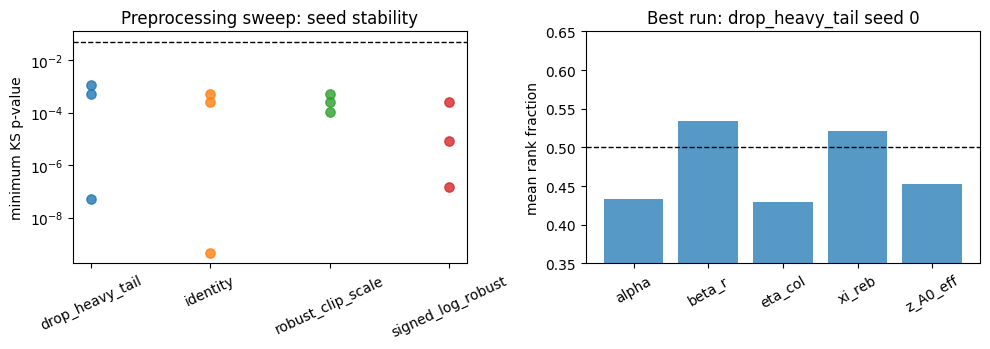

Require more than one seed with min KS p > 0.05 before treating a preprocessing variant as stable.


In [7]:
summary_by_variant = preprocess_df.groupby('preprocess')['min_ks_pvalue'].agg(['count', 'max', 'median', 'min']).sort_values('max', ascending=False)
display(summary_by_variant)
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.6))
for variant, g in preprocess_df.groupby('preprocess'):
    axes[0].scatter([variant] * len(g), g['min_ks_pvalue'], s=45, alpha=0.8)
axes[0].axhline(0.05, color='k', ls='--', lw=1.0)
axes[0].set_yscale('log')
axes[0].set_ylabel('minimum KS p-value')
axes[0].set_title('Preprocessing sweep: seed stability')
axes[0].tick_params(axis='x', rotation=25)
best = preprocess_df.sort_values('min_ks_pvalue', ascending=False).iloc[0]
rank_values = [best[f'{name}_mean_rank_frac'] for name in PARAM_NAMES]
axes[1].bar(PARAM_NAMES, rank_values, color='tab:blue', alpha=0.75)
axes[1].axhline(0.5, color='k', ls='--', lw=1.0)
axes[1].set_ylim(0.35, 0.65)
axes[1].set_ylabel('mean rank fraction')
axes[1].set_title(f"Best run: {best['preprocess']} seed {int(best['seed'])}")
axes[1].tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(FIGURES / '38_sysII_lognormal_true_n5000_preprocess_sbc.png', dpi=180, bbox_inches='tight')
plt.show()
print('Require more than one seed with min KS p > 0.05 before treating a preprocessing variant as stable.')

## 4. Experiment B - Warm-Start Ablation

This ablation compares internally consistent protocols rather than mixing them. The matched protocol remains the manuscript target. Fixed-y0 is only a geometry diagnostic.

Interpretation:

- Fixed-y0 passes while matched fails: per-draw steady-state initialization is the hard map.
- Fixed-y0 also fails: look next at summary definitions, bounded support, or weak 5-D observability.
- Never use fixed-y0 training with matched validation for manuscript numbers.

In [8]:
WARMSTART_N_TRAIN = 3000
WARMSTART_N_SBC = 120
WARMSTART_SEEDS = [0, 1, 2]
WARMSTART_BANK_PATH = DATA / f'wu2003_sbi_train_sb_lognormal_fixed_y0_n{WARMSTART_N_TRAIN}.npz'
WARMSTART_SBC_PATH = RESULTS / f'38_sysII_lognormal_fixed_y0_sbc_set_n{WARMSTART_N_SBC}.npz'
WARMSTART_SUMMARY_PATH = RESULTS / f'38_sysII_lognormal_fixed_y0_n{WARMSTART_N_TRAIN}_sbc.json'
WARMSTART_CSV_PATH = RESULTS / f'38_sysII_lognormal_fixed_y0_n{WARMSTART_N_TRAIN}_sbc.csv'

def generate_lognormal_bank(out_path, n_rows, seed, scenario_specific_warm_start):
    if out_path.exists():
        bank = np.load(out_path)
        print(f'loading existing bank: {out_path}')
        return np.asarray(bank['thetas'], dtype=np.float32), np.asarray(bank['summaries'], dtype=np.float32)
    ctrl, y0 = _structure_config(STRUCTURE)
    rng = np.random.default_rng(seed)
    theta_rows, summary_rows = [], []
    t0 = time.time()
    attempts = 0
    while len(theta_rows) < n_rows:
        attempts += 1
        th = prior_logn.sample((1,)).numpy()[0]
        s = _simulate_summary(th, ctrl, y0, STRUCTURE, NOISE_PCT, rng, scenario_specific_warm_start=scenario_specific_warm_start)
        if s is None or not np.isfinite(s).all():
            continue
        theta_rows.append(th)
        summary_rows.append(s)
        if len(theta_rows) % 250 == 0:
            print(f'[bank] {len(theta_rows)}/{n_rows}, attempts={attempts}, elapsed={time.time()-t0:.0f}s')
            np.savez(out_path.with_suffix('.partial.npz'), thetas=np.asarray(theta_rows, dtype=np.float32), summaries=np.asarray(summary_rows, dtype=np.float32), attempts=attempts, scenario_specific_warm_start=scenario_specific_warm_start)
    theta_arr = np.asarray(theta_rows, dtype=np.float32)
    summary_arr = np.asarray(summary_rows, dtype=np.float32)
    np.savez(out_path, thetas=theta_arr, summaries=summary_arr, attempts=attempts, seed=seed, scenario_specific_warm_start=scenario_specific_warm_start, prior='truncated_lognormal_centered_nominal')
    print(f'saved bank: {out_path}, theta={theta_arr.shape}, summaries={summary_arr.shape}, wall_s={time.time()-t0:.0f}')
    return theta_arr, summary_arr

fixed_theta_train, fixed_summary_train = generate_lognormal_bank(WARMSTART_BANK_PATH, WARMSTART_N_TRAIN, 20260829, scenario_specific_warm_start=False)
fixed_theta_sbc, fixed_summary_sbc = generate_lognormal_bank(WARMSTART_SBC_PATH, WARMSTART_N_SBC, 20260830, scenario_specific_warm_start=False)

loading existing bank: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/wu2003_sbi_train_sb_lognormal_fixed_y0_n3000.npz
saved bank: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/38_sysII_lognormal_fixed_y0_sbc_set_n120.npz, theta=(120, 5), summaries=(120, 66), wall_s=10


In [9]:
def train_fixed_y0_lognormal_posterior(torch_seed):
    torch.manual_seed(torch_seed)
    inference = SNPE(prior=prior_logn, density_estimator=posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS))
    inference.append_simulations(torch.tensor(fixed_theta_train, dtype=torch.float32), torch.tensor(fixed_summary_train, dtype=torch.float32))
    t0 = time.time()
    trained = inference.train(max_num_epochs=MAX_EPOCHS, validation_fraction=0.1, stop_after_epochs=STOP_AFTER_EPOCHS, show_train_summary=True)
    return inference.build_posterior(trained), time.time() - t0

def run_fixed_y0_lognormal_sbc(posterior, seed, n_post=N_POST):
    torch.manual_seed(seed)
    ranks = {name: [] for name in PARAM_NAMES}
    sample_seconds = []
    for i, (th, x_obs) in enumerate(zip(fixed_theta_sbc, fixed_summary_sbc)):
        t_sample = time.time()
        with torch.no_grad():
            samp = posterior.sample((n_post,), x=torch.tensor(x_obs, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=True).detach().cpu().numpy()
        sample_seconds.append(time.time() - t_sample)
        for k, name in enumerate(PARAM_NAMES):
            ranks[name].append(int(np.sum(samp[:, k] < th[k])))
    results = {'n_sbc': int(len(fixed_theta_sbc)), 'n_post': int(n_post), 'n_valid': int(len(fixed_theta_sbc)), 'reject_outside_prior': True, 'scenario_specific_warm_start': False, 'sample_seconds_mean': float(np.mean(sample_seconds)), 'sample_seconds_p95': float(np.percentile(sample_seconds, 95)), 'sample_seconds_max': float(np.max(sample_seconds))}
    for name in PARAM_NAMES:
        r = np.asarray(ranks[name], dtype=float)
        ks = scipy_stats.ks_1samp(r / n_post, scipy_stats.uniform.cdf)
        results[name] = {'ranks': r.astype(int).tolist(), 'ks_pvalue': float(ks.pvalue), 'mean_rank_frac': float(r.mean() / n_post)}
    results['min_ks_pvalue'] = min(results[name]['ks_pvalue'] for name in PARAM_NAMES)
    return results

fixed_results = []
for seed in WARMSTART_SEEDS:
    variant = f'lognormal_fixed_y0_n{WARMSTART_N_TRAIN}_seed{seed}'
    posterior_path = SBI_LOGS / f'wu2003_posterior_{variant}.pkl'
    if posterior_path.exists():
        with open(posterior_path, 'rb') as f:
            payload = pickle.load(f)
        posterior = payload['posterior']
        train_wall_s = float(payload.get('train_wall_s', 0.0))
        print(f'loaded {posterior_path.name}')
    else:
        posterior, train_wall_s = train_fixed_y0_lognormal_posterior(seed)
        with open(posterior_path, 'wb') as f:
            pickle.dump({'posterior': posterior, 'variant': variant, 'n_train': WARMSTART_N_TRAIN, 'torch_seed': seed, 'prior': 'truncated_lognormal_centered_nominal', 'bank_path': str(WARMSTART_BANK_PATH), 'scenario_specific_warm_start': False, 'train_wall_s': train_wall_s}, f)
    t_sbc = time.time()
    sbc = run_fixed_y0_lognormal_sbc(posterior, seed=20260831 + seed)
    row = {'experiment': 'fixed_y0', 'seed': seed, 'n_train': WARMSTART_N_TRAIN, 'n_features': int(fixed_summary_train.shape[1]), 'train_wall_s': train_wall_s, 'sbc_wall_s': time.time() - t_sbc, 'posterior_path': str(posterior_path), 'sbc': sbc}
    fixed_results.append(row)
    with open(WARMSTART_SUMMARY_PATH, 'w') as f:
        json.dump({'status': 'in_progress', 'results': fixed_results}, f, indent=2)
    pd.DataFrame([flatten_result(r) for r in fixed_results]).to_csv(WARMSTART_CSV_PATH, index=False)
with open(WARMSTART_SUMMARY_PATH, 'w') as f:
    json.dump({'status': 'complete', 'results': fixed_results, 'training_bank': str(WARMSTART_BANK_PATH), 'validation_bank': str(WARMSTART_SBC_PATH)}, f, indent=2)
fixed_df = pd.DataFrame([flatten_result(r) for r in fixed_results]).sort_values('min_ks_pvalue', ascending=False)
fixed_df.to_csv(WARMSTART_CSV_PATH, index=False)
display(fixed_df)

loaded wu2003_posterior_lognormal_fixed_y0_n3000_seed0.pkl
loaded wu2003_posterior_lognormal_fixed_y0_n3000_seed1.pkl
loaded wu2003_posterior_lognormal_fixed_y0_n3000_seed2.pkl


,experiment,seed,n_train,n_features,train_wall_s,sbc_wall_s,min_ks_pvalue,sample_seconds_mean,sample_seconds_p95,alpha_ks_pvalue,alpha_mean_rank_frac,beta_r_ks_pvalue,beta_r_mean_rank_frac,eta_col_ks_pvalue,eta_col_mean_rank_frac,xi_reb_ks_pvalue,xi_reb_mean_rank_frac,z_A0_eff_ks_pvalue,z_A0_eff_mean_rank_frac
2,fixed_y0,2,3000,66,7.761855,1.255314,0.025429,0.010377,0.015931,0.042996,0.423194,0.486298,0.503750,0.169461,0.462431,0.249912,0.536458,0.025429,0.518472
0,fixed_y0,0,3000,66,6.850287,1.426990,0.004286,0.011790,0.016668,0.025429,0.554097,0.249912,0.477986,0.004286,0.439167,0.042996,0.460417,0.070267,0.531806
1,fixed_y0,1,3000,66,12.125828,1.219874,0.000110,0.010096,0.015974,0.000246,0.576944,0.355514,0.507222,0.000110,0.609514,0.000246,0.493611,0.000110,0.568472


## 5. Experiment C - Logit Parameter-Space Scaffold

This is the structural support-geometry test. Instead of training the neural posterior directly on bounded physical parameters, transform each physical parameter to an unconstrained coordinate:

`u = logit((theta - low) / (high - low))`

Then train SNPE on `u` with a standard normal prior. For SBC, sample `u`, map to `theta`, simulate in physical space, condition the posterior in `u` space, map posterior samples back to `theta`, and compute ranks in physical space.

This is the strongest next hypothesis if preprocessing and warm-start ablation both fail. The code below is a scaffold: run it after the previous two experiments, or promote it to a dedicated production script if it is promising.

In [10]:
EPS_BOX = 1e-5
LOGIT_N_TRAIN = 3000
LOGIT_N_SBC = 120
LOGIT_SEEDS = [0, 1, 2]
LOGIT_BANK_PATH = DATA / f'wu2003_sbi_train_sb_lognormal_logit_u_n{LOGIT_N_TRAIN}.npz'
LOGIT_SUMMARY_PATH = RESULTS / f'38_sysII_lognormal_logit_u_n{LOGIT_N_TRAIN}_sbc.json'
LOGIT_CSV_PATH = RESULTS / f'38_sysII_lognormal_logit_u_n{LOGIT_N_TRAIN}_sbc.csv'

def theta_to_unit(theta):
    z = (np.asarray(theta, dtype=np.float32) - PRIOR_LOW_5D) / (PRIOR_HIGH_5D - PRIOR_LOW_5D)
    return np.clip(z, EPS_BOX, 1.0 - EPS_BOX)

def theta_to_u(theta):
    z = theta_to_unit(theta)
    return np.log(z / (1.0 - z)).astype(np.float32)

def u_to_theta(u):
    z = 1.0 / (1.0 + np.exp(-np.asarray(u, dtype=np.float32)))
    return (PRIOR_LOW_5D + z * (PRIOR_HIGH_5D - PRIOR_LOW_5D)).astype(np.float32)

u_train = theta_to_u(theta_train_pp)[:LOGIT_N_TRAIN]
x_train_logit = summary_train_pp_raw[:LOGIT_N_TRAIN]
np.savez(LOGIT_BANK_PATH, u=u_train, theta=theta_train_pp[:LOGIT_N_TRAIN], summaries=x_train_logit, source_bank=str(MATCHED_LOGN_BANK_5K))
print('logit training bank:', u_train.shape, x_train_logit.shape)
print(pd.DataFrame(u_train, columns=PARAM_NAMES).describe(percentiles=[0.05, 0.5, 0.95]).T)

logit training bank: (3000, 5) (3000, 66)
           count      mean       std       min        5%       50%       95%  \
alpha     3000.0  1.155582  1.071089 -1.232245 -0.207041  0.967366  3.185813   
beta_r    3000.0  1.101081  1.013492 -1.263033 -0.206315  0.945484  2.965583   
eta_col   3000.0  2.128002  1.233773 -0.410755  0.580910  1.876297  4.460419   
xi_reb    3000.0  1.102787  1.050188 -1.078057 -0.180968  0.901535  3.093050   
z_A0_eff  3000.0  1.366847  1.154063 -1.214052 -0.078524  1.158374  3.589339   

                max  
alpha      7.837287  
beta_r    10.532948  
eta_col    9.749965  
xi_reb     9.519065  
z_A0_eff  11.511559  


In [ ]:
# Scaffold only: this trains in u-space using a wide Gaussian prior approximation.
# If it improves SBC, the production version should define the exact induced prior in u-space.
from torch.distributions import Independent, Normal

u_mean = torch.tensor(u_train.mean(axis=0), dtype=torch.float32)
u_std = torch.tensor(np.maximum(u_train.std(axis=0), 1e-3), dtype=torch.float32)
prior_u = Independent(Normal(u_mean, u_std), 1)

def train_logit_u_posterior(torch_seed):
    torch.manual_seed(torch_seed)
    inference = SNPE(prior=prior_u, density_estimator=posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS))
    inference.append_simulations(torch.tensor(u_train, dtype=torch.float32), torch.tensor(x_train_logit, dtype=torch.float32))
    t0 = time.time()
    trained = inference.train(max_num_epochs=MAX_EPOCHS, validation_fraction=0.1, stop_after_epochs=STOP_AFTER_EPOCHS, show_train_summary=True)
    return inference.build_posterior(trained), time.time() - t0

def run_logit_u_sbc(posterior, seed, n_post=N_POST):
    torch.manual_seed(seed)
    ranks = {name: [] for name in PARAM_NAMES}
    sample_seconds = []
    for i, (theta_true, x_obs) in enumerate(zip(theta_sbc_pp[:LOGIT_N_SBC], summary_sbc_pp_raw[:LOGIT_N_SBC])):
        t_sample = time.time()
        with torch.no_grad():
            u_samp = posterior.sample((n_post,), x=torch.tensor(x_obs, dtype=torch.float32), show_progress_bars=False).detach().cpu().numpy()
        theta_samp = u_to_theta(u_samp)
        sample_seconds.append(time.time() - t_sample)
        for k, name in enumerate(PARAM_NAMES):
            ranks[name].append(int(np.sum(theta_samp[:, k] < theta_true[k])))
    results = {'n_sbc': int(LOGIT_N_SBC), 'n_post': int(n_post), 'n_valid': int(LOGIT_N_SBC), 'parameter_space': 'logit_u', 'sample_seconds_mean': float(np.mean(sample_seconds)), 'sample_seconds_p95': float(np.percentile(sample_seconds, 95)), 'sample_seconds_max': float(np.max(sample_seconds))}
    for name in PARAM_NAMES:
        r = np.asarray(ranks[name], dtype=float)
        ks = scipy_stats.ks_1samp(r / n_post, scipy_stats.uniform.cdf)
        results[name] = {'ranks': r.astype(int).tolist(), 'ks_pvalue': float(ks.pvalue), 'mean_rank_frac': float(r.mean() / n_post)}
    results['min_ks_pvalue'] = min(results[name]['ks_pvalue'] for name in PARAM_NAMES)
    return results

# Uncomment to run after Experiments A and B.
# logit_results = []
# for seed in LOGIT_SEEDS:
#     posterior_u, train_wall_s = train_logit_u_posterior(seed)
#     sbc = run_logit_u_sbc(posterior_u, seed=420000 + seed)
#     row = {'experiment': 'logit_u', 'seed': seed, 'n_train': LOGIT_N_TRAIN, 'n_features': int(x_train_logit.shape[1]), 'train_wall_s': train_wall_s, 'sbc_wall_s': None, 'sbc': sbc}
#     logit_results.append(row)
#     pd.DataFrame([flatten_result(r) for r in logit_results]).to_csv(LOGIT_CSV_PATH, index=False)
# with open(LOGIT_SUMMARY_PATH, 'w') as f:
#     json.dump({'status': 'complete', 'results': logit_results, 'training_bank': str(LOGIT_BANK_PATH)}, f, indent=2)

## 6. Decision Guide

Use seed stability as the primary criterion. A viable repair should produce at least two passing seeds at the reduced diagnostic budget before scaling up.

- **Preprocessing passes:** rerun the winning variant with larger SBC, then combine with the lognormal prior in a larger true simulator bank.
- **Only fixed-y0 passes:** the matched steady-state warm-start map is the likely source of difficult geometry; inspect summary sensitivity to `_matched_y0(theta)`.
- **Logit-u passes:** bounded support was the main geometry issue; implement this as a clean pipeline rather than relying on `reject_outside_prior=True`.
- **All fail:** reduce the inference target temporarily. Try 3-D or 4-D subsets to identify whether `xi_reb` and/or `z_A0_eff` are destabilizing the full 5-D posterior.

## 7. Analysis of Completed Repair Experiments

The completed preprocessing and fixed-y0 experiments narrow the diagnosis.

**Preprocessing did not solve calibration.** Across `identity`, `robust_clip_scale`, `signed_log_robust`, and `drop_heavy_tail`, no variant produced a passing seed at `N_SBC=120`, `N_POST=120`. The best case was `drop_heavy_tail`, seed 0, with min-KS `p = 1.10e-3`, still far below the 0.05 threshold. This means the extreme `V_norm*` and `Q_j*` summaries are real contributors, but simple clipping, signed-log compression, or dropping those dimensions does not repair the full posterior.

**Fixed-y0 improved but still failed.** The fixed-nominal warm-start ablation gave the best overall repair signal: seed 2 reached min-KS `p = 2.54e-2`. That is closer to calibration than the matched 5k true-lognormal baseline (`2.21e-3`) and much better than most preprocessing variants, but it remains a formal SBC failure. This suggests the matched steady-state map contributes to the geometry, but is not the sole root cause.

**Current working diagnosis.** The remaining failure is most consistent with bounded-support geometry plus weak full 5-D identifiability, especially for `xi_reb` and `z_A0_eff`. The next diagnostic should train in unconstrained parameter coordinates and evaluate ranks after mapping samples back to physical space.

In [13]:
logit_results = []
for seed in LOGIT_SEEDS:
    posterior_u, train_wall_s = train_logit_u_posterior(seed)
    sbc = run_logit_u_sbc(posterior_u, seed=420000 + seed)
    row = {'experiment': 'logit_u', 'seed': seed, 'n_train': LOGIT_N_TRAIN, 'n_features': int(x_train_logit.shape[1]), 'train_wall_s': train_wall_s, 'sbc_wall_s': None, 'sbc': sbc}
    logit_results.append(row)
    pd.DataFrame([flatten_result(r) for r in logit_results]).to_csv(LOGIT_CSV_PATH, index=False)
with open(LOGIT_SUMMARY_PATH, 'w') as f:
    json.dump({'status': 'complete', 'results': logit_results, 'training_bank': str(LOGIT_BANK_PATH)}, f, indent=2)

/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [1, 3, 5, 7, 9, 15, 17, 18, 21, 22, 23, 31, 32, 50, 54, 60] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 71 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 71
        Best validation performance: -3.7502
        -------------------------
        


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [1, 3, 5, 7, 9, 15, 17, 18, 21, 22, 23, 31, 32, 50, 54, 60] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 79 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 79
        Best validation performance: -3.6580
        -------------------------
        


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [1, 3, 5, 7, 9, 15, 17, 18, 21, 22, 23, 31, 32, 50, 54, 60] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 98 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 98
        Best validation performance: -3.8777
        -------------------------
        
